很多外部工具的功能其实是通用的，例如查询时间、查询天气、网络搜索、操作本地文件夹等等等等，如果有一种规范，能够减少重复造轮子的时间，一个人开发完成后全体开发者都能共享，那么整体的研发效率都将得到大幅提高。

## 什么是MCP

**定义：**

MCP（Model Context Protocol，模型上下文协议） ，2024年11月底，由 Claude母公司Anthropic 推出的一种开放标准，旨在统一大模型与外部数据源和工具之间的**通信协议**。MCP的主要目的在于解决当前AI大模型因数据孤岛限制而无法充分发挥潜力的难题,MCP使得AI应用能够安全地访问和操作本地及远程数据,为AI应用提供了连接万物的接口。我们可以将MCP简单理解为智能体外部工具开发的一种通用规范。

MCP 就像 USB一样，可以让不同设备能够通过相同的接口连接在一起。
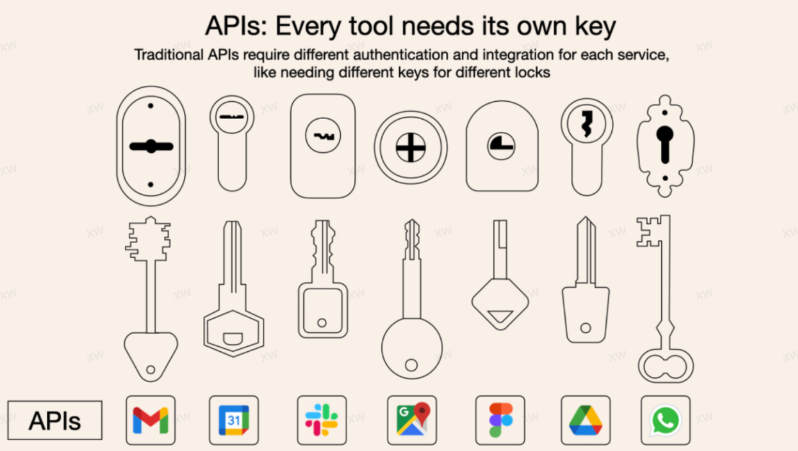
![image-20250825165038557](image-20250825165038557.png)


MCP 是一个开放协议，它标准化了应用程序向大型语言模型 (LLM) 提供上下文的方式。MCP 就像 AI 应用程序的 USB-C 端口一样。正如 USB-C 提供了一种标准化的方式将您的设备连接到各种外围设备和配件一样，MCP 也提供了一种标准化的方式将 AI 模型连接到不同的数据源和工具。MCP 使您能够在 LLM 之上构建代理和复杂的工作流，并将您的模型与世界连接起来。<br>
**通信协议**：通信协议是通信双方约定的一套“规则”，规定了数据如何表示、如何打包/传输、何时发送/确认、出错如何处理等，从而保证不同设备/软件能“听得懂、对得上、传得稳”。


MCP 提供：

+ 越来越多的预建集成(工具) 可供您的 LLM 直接插入

+ 为 AI 应用程序构建自定义集成的标准化方法

+ 每个人都可以自由实施和使用的开放协议

+ 在不同应用程序之间切换并随身携带上下文的灵活性

MCP 通过定义标准化的接口和协议，使 LLM 能够动态访问和集成以下内容：

1. **外部数据源**：如数据库、API、文档库等，为 LLM 提供实时或历史数据。
2. **工具和服务**：如计算工具、搜索引擎、第三方服务等，扩展 LLM 的功能。
3. **上下文管理**：动态维护 LLM 的对话上下文，确保连贯性和一致性。

![image-20250825164739246](image-20250825164739246.png)


## MCP 的架构
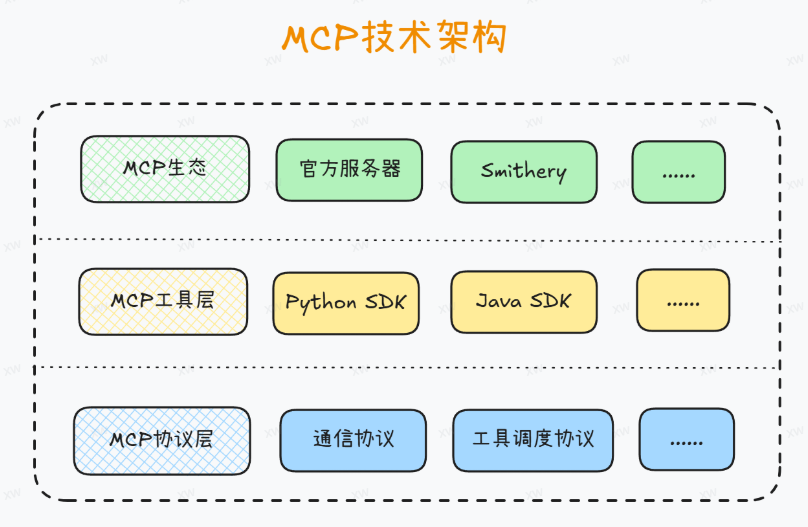 <br>
MCP 的架构由四个关键部分组成：

1. **主机（Host）**：主机是指连接到计算机网络中的任何设备，能够与网络中的其他设备进行通信和数据交换。主机可以是物理设备，也可以是虚拟设备。
2. **客户端（Client）**：客户端是主机与服务器之间的桥梁。它与服务器保持一对一的连接，负责消息路由、能力管理、协议协商和订阅管理等。客户端确保主机和服务器之间的通信清晰、安全且高效。
3. **服务器（Server）**：服务器是提供外部数据和工具的组件。它通过工具、资源和提示模板为大型语言模型提供额外的上下文和功能。例如，一个服务器可以提供与Gmail、Slack等外部服务的API调用。
4. **基础协议（Base Protocol）**：基础协议定义了主机、客户端和服务器之间如何通信。它包括消息格式、生命周期管理和传输机制等。

**MCP client 充当 LLM 和 MCP server 之间的桥梁，MCP client 的工作流程如下：**

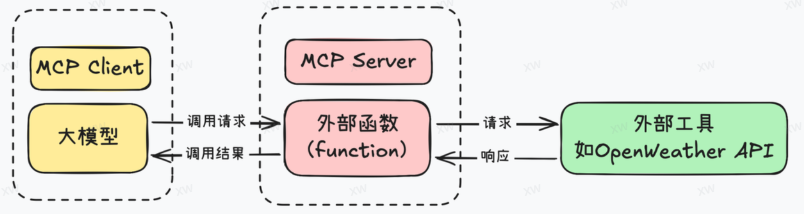

+ MCP client 首先从 MCP server 获取可用的工具列表。

+ 将用户的查询连同工具描述通过 function calling 一起发送给 LLM。

+ LLM 决定是否需要使用工具以及使用哪些工具。

+ 如果需要使用工具，MCP client 会通过 MCP server 执行相应的工具调用。

+ 工具调用的结果会被发送回 LLM。

+ LLM 基于所有信息生成自然语言响应。

+ 最后将响应展示给用户。


## **MCP的工作原理：**

MCP 通过定义**标准化的数据格式和通信协议**，实现 LLM 与外部资源的交互。

MCP 使用 **JSON-RPC 2.0** 作为消息格式，通过标准的请求、响应和通知消息进行通信。

MCP 支持多种传输机制，包括本地的标准输入/输出（**Stdio**）和基于HTTP的服务器发送事件（**SSE**）。

MCP的生命周期包括初始化、运行和关闭三个阶段，确保连接的建立、通信和终止都符合协议规范。


那么再了解工具调用的流程之后请你们告诉我，你们认为MCP为什么需要标准化的数据格式？下来再思考一下


### **JSON-RPC 2.0** 

JSON-RPC 2.0 是一种轻量级的远程过程调用（Remote Procedure Call, RPC）协议，使用 JSON 作为数据格式。它的核心目标是简化远程调用的复杂性，使其看起来像本地调用一样简单，同时屏蔽底层网络细节。以下是 JSON-RPC 2.0 的一些关键特点和结构：

------

**特点**

1. **轻量化**：基于 JSON 格式，易于解析和传输。
2. **无状态**：协议本身不依赖于会话状态，适合分布式系统。
3. **传输协议无关**：可以通过 HTTP、WebSocket、TCP 等多种传输协议实现。
4. **双向通信**：支持请求-响应模式，同时允许服务端主动发送通知。
5. **错误处理**：提供标准化的错误响应格式，便于调试和问题定位。

------

**消息结构**

JSON-RPC 2.0 的消息分为三种类型：**请求**、**响应** 和 **通知**。

**1. 请求消息**

用于客户端向服务端发起调用请求，包含以下字段：

```json
{
  "jsonrpc": "2.0",
  "method": "methodName",
  "params": [param1, param2],
  "id": 1
}
```

- `jsonrpc`: 必须为 `"2.0"`，表示协议版本。
- `method`: 调用的方法名称。
- `params`: 可选，方法的参数，可以是数组或对象。
- `id`: 请求的唯一标识符，用于匹配响应。

**2. 响应消息**

服务端对请求的响应，包含以下字段：

```json
{
  "jsonrpc": "2.0",
  "result": "success",
  "id": 1
}
```

- `result`: 方法执行的返回结果。
- `id`: 与请求中的 `id` 对应。

如果发生错误：

```json
{
  "jsonrpc": "2.0",
  "error": {
    "code": -32601,
    "message": "Method not found"
  },
  "id": 1
}
```

- `error`: 包含错误代码和描述信息。

**3. 通知消息**

服务端无需响应的消息，类似于单向调用：

```json
{
  "jsonrpc": "2.0",
  "method": "notifyEvent",
  "params": {"key": "value"}
}
```

- 没有 `id` 字段，表示不需要响应。


### MCP的整个工作流程：

![image-20250826114152080](image-20250826114152080.png)

**MCP解决的最大痛点，就是Agent开发中调用外部工具的技术门槛过高的问题。**

### langgraph调用MCP

- 阿里云百炼：https://bailian.console.aliyun.com/?tab=mcp<br>
- 魔搭社区MCP广场：https://www.modelscope.cn/mcp

#### 基于HTTP的服务器发送事件（**SSE**）

**SSE**: 其实是一种基于HTTP协议实现的长连接协议，只不过SSE协议是一种从服务端向客户端单向推送数据的长连接协议。也就是高德地图需要提供一个HTTP服务，然后客户端可以和这个HTTP服务建立一个长连接，这样客户端就可以不断的访问高德地图的HTTP服务，获得高德地图的服务数据。这时候的工作机制其实和以往我们熟悉的基于HTTP的工作机制本质上是很像的。只是服务端的性能压力会大一点而已。

In [ ]:
#pip install llangchain_mcp_adapters

from langchain_mcp_adapters.client import MultiServerMCPClient
import asyncio
from langchain_ollama import ChatOllama
from langchain.agents import create_agent


llm = ChatOllama(model="qwen3:8b",base_url="http://localhost:11434")

mcp_server_config = {
    "12306-mcp": {
     "transport": "sse",
      "url": "https://mcp.api-inference.modelscope.net/22d13455491e40/sse"
    },
    # "mcp_math": {
    #     "transport": "sse",  
    #     "url": "http://localhost:8000/sse"  # 或使用 自己写MCP  SSE模式
    # }
  }  

client = MultiServerMCPClient(mcp_server_config)

async def create_agent_test():
        # 获取MCP工具
        tools = await client.get_tools()

        agent = create_agent(llm, tools)
        return agent

async def test_agent():
    agnet = await create_agent_test()
    result =await agnet.ainvoke({"messages":[("human","成都到北京的火车最早的是几点?")]})
    print(result)

if __name__ == "__main__":
    asyncio.run(test_agent())

#### 本地的标准输入/输出（**Stdio**)
**STDIO**: 这种工作机制的本质是在客户端本地执行一个应用程序，然后通过应用程序获得对应的结果。这时候MCP的核心问题就出来了。MCP的服务是由MCP的服务提供者设计的，但是执行却是在客户端的机器执行。也就是说，这给服务提供者提供了一种操作客户端机器的机会。这里面会带来多少安全问题？

使用stdio这种机制需要安装Node.js

[Node.js — Download Node.js®](https://nodejs.org/en/download)

只需要替换我们sse中的config就行了

In [ ]:
mcp_server_config = {
    "12306-mcp": {
      "args": [
        "-y",
        "12306-mcp"
      ],
      "command": "npx",
      "transport": "stdio" #本地使用nodejs 运行
    }}


client = MultiServerMCPClient(
     mcp_server_config
)


### **Dify中去调用MCP**

dify网址：https://cloud.dify.ai/tools?category=mcp

魔塔社区：https://modelscope.cn/my/overview

![image-20250827113947378](image-20250827113947378.png)


填入你获取到的URL地址：

![image-20250827114359057](image-20250827114359057.png)


然后你就可以在Agengt中使用你的MCP工具

 ![](C:\Users\guaizi\Desktop\教学文档\大模型\MCP\image-20250827160220355.png)


请大家使用魔塔社区上的MCP工具：[MCP 广场 · 魔搭社区](https://www.modelscope.cn/mcp)


### 开发自己的MCP工具

 GitHub的地址

https://github.com/modelcontextprotocol 



UV安装地址：

https://docs.astral.sh/uv/getting-started/installation/

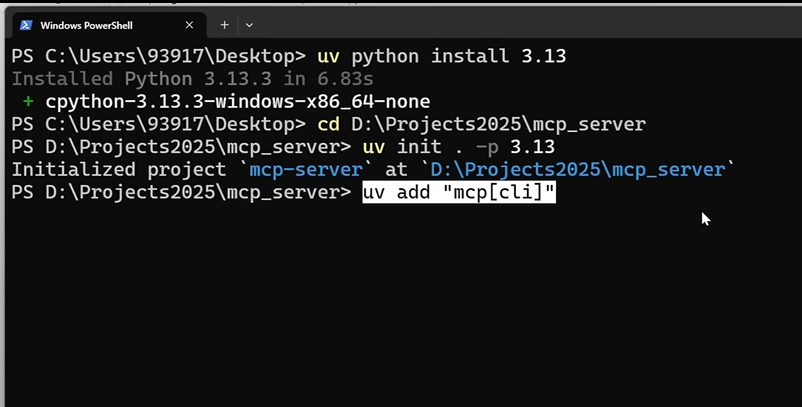


In [ ]:
from mcp.server.mcpserver import MCPServer

mcp = MCPServer("library")
STUDENTS = {
    "2024001": {"name": "张三", "borrowed": 2, "overdue": 0},
    "2024002": {"name": "李四", "borrowed": 5, "overdue": 1},
}

STOCK = {
    "三体": 3,
    "红楼梦": 0,
    "Python入门": 5,
}

# ---------- Resource ----------
@mcp.resource("library://rules")
def library_rules() -> str:
    """图书馆借阅规则"""
    return (
        "1. 每人最多借 5 本\n"
        "2. 借期 30 天，可续借 1 次\n"
        "3. 逾期每天 0.5 元\n"
        "4. 有逾期未还，禁止继续借书\n"
        "5. 参考书不可外借"
    )

@mcp.resource("student://{student_id}")
def student_profile(student_id: str) -> str:
    """按学号读取学生借阅档案"""
    info = STUDENTS.get(student_id)
    if not info:
        return f"未找到学号 {student_id}"
    return (
        f"学号:{student_id}, 姓名:{info['name']}, "
        f"已借:{info['borrowed']}本, 逾期:{info['overdue']}本"
    )

# ---------- Tool ----------
@mcp.tool()
def check_stock(book_name: str) -> str:
    """查询某本书当前可借数量"""
    n = STOCK.get(book_name, 0)
    return f"《{book_name}》可借数量：{n}"

@mcp.tool()
def borrow_book(student_id: str, book_name: str) -> str:
    """为学生办理借书"""
    student = STUDENTS.get(student_id)
    if not student:
        return f"失败：学号 {student_id} 不存在"
    if student["overdue"] > 0:
        return f"失败：{student['name']} 有逾期图书，禁止借阅"
    if student["borrowed"] >= 5:
        return f"失败：{student['name']} 已借满 5 本"

    n = STOCK.get(book_name, 0)
    if n <= 0:
        return f"失败：《{book_name}》暂无库存"

    STOCK[book_name] -= 1
    student["borrowed"] += 1
    return (
        f"成功：{student['name']} 借到《{book_name}》，"
        f"当前已借 {student['borrowed']} 本，"
        f"剩余库存 {STOCK[book_name]} 本"
    )

if __name__ == "__main__":
    # SSE：服务端独立监听 HTTP 端口
    #  # 本机+局域网都可访问
    mcp.run(transport="sse", host="0.0.0.0", port=8000)



In [ ]:
#新版本langchian有个一单独的包在做结构化输入与加载
from langchain_openai import ChatOpenAI
from pydantic import BaseModel,Field
model = ChatOpenAI(model="qwen3.7-plus", base_url="https://llm-0vksjtr7rk6p888v.cn-beijing.maas.aliyuncs.com/compatible-mode/v1",
api_key="sk-ws-H.EIHPLED.PegD.MEUCIAHdPmKVll0fM1N80lYClTAFZYd-kxBCq8QjQ8F0eGiaAiEAmfQJY2lyqPejgyxHai48M9Yre0p2rNGs2WX2yEuksm0",
extra_body={"enable_thinking": False})


# library_client_sse.py
import asyncio
from langchain_openai import ChatOpenAI
from langgraph.prebuilt import create_react_agent
from langchain_mcp_adapters.client import MultiServerMCPClient

# 和 notebook 一样：SSE 配 url，不再配 command/args
mcp_server_config = {
    "library": {
        "transport": "sse",
        "url": "http://192.168.2.147:8000/sse",
    }
}

client = MultiServerMCPClient(mcp_server_config)

async def main():
    # 1) 获取 Tool（Agent 可调用）
    tools = await client.get_tools()
    print("可用工具:", [t.name for t in tools])

    # 2) 读取 Resource（注入上下文）
    async with client.session("library") as session:
        rules = await session.read_resource("library://rules")
        profile = await session.read_resource("student://2024001")

        rules_text = rules.contents[0].text
        profile_text = profile.contents[0].text
        print("规则:\n", rules_text)
        print("学生档案:\n", profile_text)

        # 可选：列出所有 resource
        all_resources = await session.list_resources()
        print("资源列表:")
        for res in all_resources.resources:
            print(" -", res.uri)

    # 3) 创建 Agent：Resource 进 prompt，Tool 给模型调用
    system_prompt = f"""你是校园图书管理员助手。
请严格依据以下信息回答，必要时调用工具。

【借阅规则】
{rules_text}

【当前学生档案】
{profile_text}

规则：
- 先判断能不能借（规则 + 档案）
- 需要库存时调用 check_stock
- 用户确认借书时再调用 borrow_book
"""

    
    agent = create_react_agent(model, tools, prompt=system_prompt)

    question = "学号 2024001，我想借《三体》，可以吗？如果可以请帮我办理。"
    result = await agent.ainvoke({"messages": [("user", question)]})
    print("\n最终回答:\n", result["messages"][-1].content)

if __name__ == "__main__":
    asyncio.run(main())